<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/4_Aprendizaje_no_supervisado/3_Taller_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)  
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)  
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# **Taller: Creación de un Índice de Clima de Inversión con Análisis de Componentes Principales (PCA)**

**IMPORTANTE**: Guarda una copia de este notebook en tu Google Drive o computador.

**Taller en parejas**

**Nombres estudiantes:**

-Juan Felipe Pacheco
-Isabella Ramirez Santamaria

**Forma de entrega:**

- Nombrar el archivo de la siguiente forma:“Taller_PCA_apellidos.ipynb”.
- Suba el Jupyter Notebook a su cuenta en Github y envíe el link en el siguiente Forms: https://forms.cloud.microsoft/r/ZZX1AFUsPP.

**IMPORTANTE:** No se recibirán talleres en Google Colab, el notebook debe estar subido en Github.

**Plazo de entrega:**

21 de octubre de 2026, máximo a las 11:59 p.m. Tenga en cuenta que luego de esa hora el formulario en forms se cierra. El Jupupyter Notebook también debe quedar subido en Github antes de esa hora.

**Instrucciones Generales:**

Completa el código en las celdas marcadas con `### TU CÓDIGO AQUÍ ###`. Puedes añadir más celdas si lo requieres.

### Contexto

**Escenario:** Eres un científico de datos recién contratado como consultor experto por el **Ministerio de Comercio, Industria y Turismo (MinCIT)** de Colombia. Tu tarea principal es crear un **'Índice de Clima para la Inversión'** cuantitativo que permita clasificar y comparar el entorno competitivo de los países de América Latina y el Caribe. Este índice orientará las estrategias de integración regional y las políticas para atraer Inversión Extranjera Directa (IED).

**Objetivo:** Utilizando la base de datos de indicadores provista (preparada para este análisis) y la técnica de **Análisis de Componentes Principales (PCA)**, deberás extraer la "variable latente" que resume el clima de inversión, interpretar sus pesos económicos y presentar un ranking de países con recomendaciones ejecutivas.


## Ejercicio 1: Configuración Inicial, Carga y Exploración de Datos

1.1 Importa las librerías necesarias

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA


In [7]:
# Configuraciones de visualización
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

1.2 Carga el dataset "Indicators.csv" que se encuentra en el repositorio del curso, carpeta "datasets". El dataframe debe llamarse "df_indicators".

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
df_indicators = pd.read_csv('/content/drive/MyDrive/TALLER IA /Indicators.csv')

In [10]:
# Debe ser (121, 4)
print("Dimensiones del DataFrame Indicators:")
print(df_indicators.shape)

Dimensiones del DataFrame Indicators:
(121, 4)


In [11]:
print("\nInformación general del DataFrame:")
df_indicators.info()


Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CountryCode    121 non-null    object 
 1   IndicatorCode  121 non-null    object 
 2   Year           121 non-null    int64  
 3   Value          121 non-null    float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.9+ KB


1.3 Carga el dataset "Country.csv" que se encuentra en el repositorio del curso, carpeta "datasets". El dataframe debe llamarse "df_countries".

In [12]:
df_countries = pd.read_csv('/content/drive/MyDrive/TALLER IA /Country.csv')

In [13]:
# Debe ser (14, 3)
print("Dimensiones del DataFrame Countries:")
print(df_countries.shape)

Dimensiones del DataFrame Countries:
(14, 3)


In [14]:
print("\nInformación general del DataFrame:")
df_countries.info()


Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   CountryCode  14 non-null     object
 1   ShortName    14 non-null     object
 2   Region       14 non-null     object
dtypes: object(3)
memory usage: 468.0+ bytes


### Ejercicio 2: Selección y Preparación de Datos

Para el análisis del MinCIT, hemos preseleccionado un conjunto de variables clave.

2.1. Utiliza el diccionario para modificar los códigos de los indicadores por sus descripciones

In [15]:
nombre_indicadores = {
    'NV.AGR.TOTL.ZS': 'Agricultura (% del PIB)',
    'NE.TRD.GNFS.ZS': 'Comercio (% del PIB)',
    'NY.GDP.MKTP.KD.ZG': 'Crecimiento del PIB (%)',
    'FP.CPI.TOTL.ZG': 'Inflación (%)',
    'GC.DOD.TOTL.GD.ZS': 'Deuda del gob. central (% del PIB)',
    'SE.XPD.TOTL.GD.ZS': 'Gasto en educación (% del PIB)',
    'SH.XPD.CHEX.GD.ZS': 'Gasto en salud (% del PIB)',
    'IQ.CPA.BREG.XQ': 'Facilidad para hacer negocios',
    'IC.LGL.DURS': 'Días para cumplir contratos',
    'TX.VAL.MRCH.XD.WD': 'Exportaciones (US$)',
    'TM.VAL.MRCH.XD.WD': 'Importaciones (US$)'
}

In [16]:
df_indicators['IndicatorCode'] = df_indicators['IndicatorCode'].map(nombre_indicadores)
display(df_indicators.head())

,CountryCode,IndicatorCode,Year,Value
0,CHL,Agricultura (% del PIB),2014,6.75
1,CHL,Comercio (% del PIB),2014,74.31
2,CHL,Crecimiento del PIB (%),2014,7.65
3,CHL,Inflación (%),2014,12.62
4,CHL,Deuda del gob. central (% del PIB),2014,42.83


2.2. Utiliza pivot table para crear un nuevo dataframe donde se encuentren los países como filas y los indicadores como columnas. Llama a este dataframe "df_pivot". No olvides colocar .reset_index() para que la columna de código de países quede como una columna y no como el índice.

In [17]:
df_pivot = df_indicators.pivot_table(index='CountryCode', columns='IndicatorCode', values='Value').reset_index()
display(df_pivot.head())

IndicatorCode,CountryCode,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%)
0,ARG,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28
1,BOL,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05
2,BRA,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60
3,CHL,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62
4,COL,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61


2.3. Crea el dataframe "df_final", realizando un merge entre "df_pivot" y "df_countries" con el fin de agregar el nombre de los países.

In [18]:
df_final = pd.merge(df_pivot, df_countries, on='CountryCode', how='inner')
display(df_final.head())

,CountryCode,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),ShortName,Region
0,ARG,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28,Argentina,Latin America & Caribbean
1,BOL,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05,Bolivia,Latin America & Caribbean
2,BRA,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60,Brasil,Latin America & Caribbean
3,CHL,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,Chile,Latin America & Caribbean
4,COL,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,Colombia,Latin America & Caribbean


2.4. Elimina las columnas "Region" y "CountryCode" y establece la columna 'ShortName' como el índice del dataframe

In [19]:
df_final = df_final.drop(columns=['Region', 'CountryCode'])
df_final = df_final.set_index('ShortName')
display(df_final.head())

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%)
ShortName,,,,,,,,,,,
Argentina,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28
Bolivia,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05
Brasil,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60
Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62
Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61


### Ejercicio 3: Limpieza de Datos (Imputación de Valores Faltantes)

En la vida real de un economista, los datos tienen huecos. El PCA requiere bases completas. Usaremos una estrategia de imputación por la media para resolver los NaN.

3.1. Revisa cuántos valores faltantes hay en cada columna

In [20]:
missing_values = df_final.isnull().sum()
display(missing_values)

,0
Agricultura (% del PIB),4
Comercio (% del PIB),3
Crecimiento del PIB (%),0
Deuda del gob. central (% del PIB),4
Días para cumplir contratos,2
Exportaciones (US$),3
Facilidad para hacer negocios,5
Gasto en educación (% del PIB),3
Gasto en salud (% del PIB),4
Importaciones (US$),3


3.2. Para cada columna, utiliza el promedio del resto de países de Latinoamérica para imputar los valores faltantes. El resultado debe quedar en un dataframe llamado "df_final_imputed". Al final revisa que no haya quedado ningún valor faltante en las columnas del dataframe.

In [21]:
df_final_imputed = df_final.fillna(df_final.mean())
print("Valores faltantes por columna en df_final_imputed:")
display(df_final_imputed.isnull().sum())

Valores faltantes por columna en df_final_imputed:


,0
Agricultura (% del PIB),0
Comercio (% del PIB),0
Crecimiento del PIB (%),0
Deuda del gob. central (% del PIB),0
Días para cumplir contratos,0
Exportaciones (US$),0
Facilidad para hacer negocios,0
Gasto en educación (% del PIB),0
Gasto en salud (% del PIB),0
Importaciones (US$),0


### Ejercicio 4: Matriz de Correlaciones y Estandarización de Variables

4.1. Grafica un mapa de calor para ver las correlaciones entre las variables.

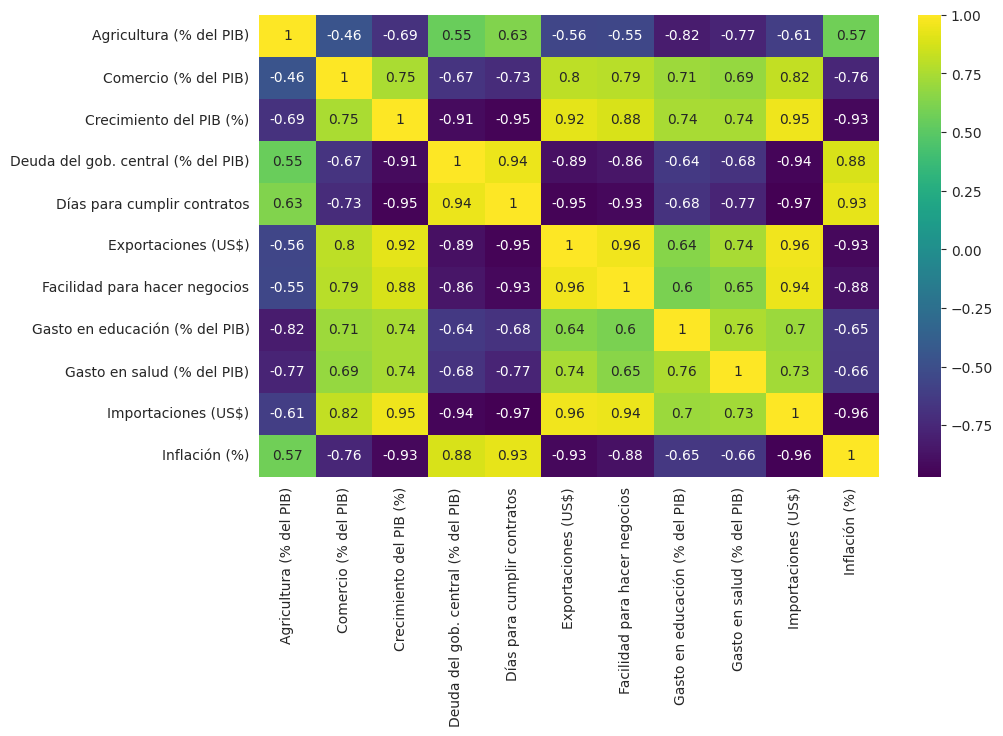

In [22]:
corr = df_final_imputed.corr().round(2)
sns.heatmap(corr, annot=True, cmap='viridis')
plt.show()

4.2. Interpreta los resultados resaltando las correlaciones más relevantes.

La matriz de correlacion nos muestra relaciones importantes entre crecimiento economico, la inflacion,la deuda publica y condiciones institucionales.El crecimiento del PIB tiene una fuerte asociacion positiva muy fuerte con las exportaciones y las importaciones,mientras que por su lado la inflacion muestra una relacion negativa muy fuerte con estas variables. Asimismo la facilidad de hacer negocios esta estrechamente relacionada con el desempeño comercial. Esto nos permite formular una hipotesis relacionada a factores de desarrollo economico.


4.3. Las exportaciones están en miles de millones de dólares y el crecimiento en porcentajes de un dígito. PCA busca varianzas, por lo que estandarizar (Media 0, Desviación 1) es un paso matemático obligatorio para no sesgar el modelo hacia las variables nominales grandes.  Estandariza todas las variables del dataframe y almacena el resultado en X_scaled.

In [23]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_final_imputed)
print("Dimensiones de X_scaled:", X_scaled.shape)

Dimensiones de X_scaled: (14, 11)


### Ejercicio 5: Aplicación de PCA

Vamos a correr PCA para identificar el número de componentes. Buscamos capturar la mayor cantidad de información (varianza) con la menor cantidad de dimensiones.

5.1. Corre PCA sobre X_scaled y calcula la varianza acumulada. Almacénala en la variable "varianza_acumulada".

In [38]:
pca = PCA()
pca.fit(X_scaled)
varianza_acumulada = np.cumsum(pca.explained_variance_ratio_)
print("Varianza acumulada por componente:\n", varianza_acumulada)

Varianza acumulada por componente:
 [0.80432386 0.89486154 0.93597174 0.95991133 0.97641891 0.9864744
 0.99249496 0.99665217 0.99895635 0.99961687 1.        ]


5.2. Similar a como lo vimos en clase, grafica la varianza explicada acumulada por componente.

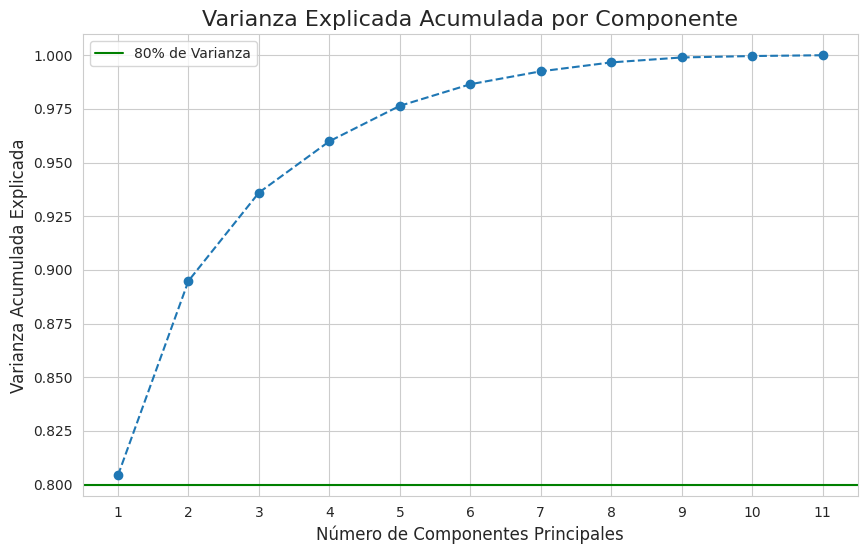

In [34]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o', linestyle='--')
plt.title('Varianza Explicada Acumulada por Componente', fontsize=16)
plt.xlabel('Número de Componentes Principales', fontsize=12)
plt.ylabel('Varianza Acumulada Explicada', fontsize=12)
plt.axhline(y=0.8, color='g', linestyle='-', label='80% de Varianza')
plt.xticks(range(1, len(varianza_acumulada) + 1))
plt.legend()
plt.show()

5.3. Realiza un análisis del gráfico anterior.

El gráfico muestra que el primer componente principal explica aproximadamente el 80,5 % de la variabilidad total de los datos, lo que indica que una gran parte de la información se puede resumir en una sola dimensión. Al incorporar más componentes, la varianza explicada aumenta progresivamente, alcanzando cerca del 93,6 % con tres componentes y el 97,6 % con cinco.

Desde una perspectiva económica, este resultado es importante porque permite reducir la cantidad de variables que se deben analizar sin perder una proporción significativa de la información. Por ejemplo, cuando se estudian indicadores económicos relacionados con el crecimiento, el empleo, la inflación o los ingresos, el análisis de componentes principales puede ayudar a identificar patrones comunes y simplificar la interpretación de los datos.

En conclusión, si el objetivo es simplificar el análisis, un solo componente podría ser suficiente para explicar más del 80 % de la variabilidad. Sin embargo, si se busca una representación más completa de la información económica, sería conveniente utilizar entre tres y cinco componentes principales. La decisión dependerá del nivel de precisión que requiera el estudio y de la importancia de conservar la información restante.

### Ejercicio 6: Interpretación Económica de los Componentes (Loadings)

Nos vamos a quedar con un solo componente. Vamor a analizar qué variables originales alimentan a este componente.

6.1. Corre nuevamente el PCA, pero ahora indicando que tenga en cuenta solo 1 componente. Almacena el modelo en "pca_final" y los resultados en "X_pca".

In [33]:
pca_final = PCA(n_components=1)
X_pca = pca_final.fit_transform(X_scaled)
print("Dimensiones de X_pca:", X_pca.shape)

Dimensiones de X_pca: (14, 1)


6.2. Grafica el mapa de calor de los loadings como lo vimos en clase

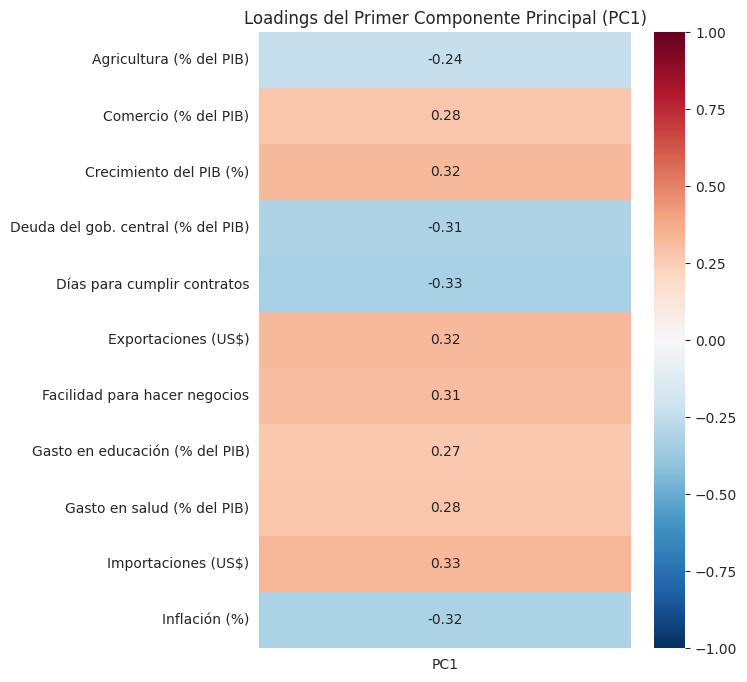

In [39]:
loadings = pd.DataFrame(
    pca_final.components_.T,
    columns=['PC1'],
    index=df_final_imputed.columns
)

plt.figure(figsize=(6, 8))
sns.heatmap(loadings, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, center=0)
plt.title('Loadings del Primer Componente Principal (PC1)')
plt.show()

6.3. Realiza una interpretación de los loadings. ¿Cuáles variables tienen las cargas altas y positivas y cuáles las cargas altas y negativas? De acuerdo con este análisis, ¿consideras que efectivamente podemos utilizar el componente 1 como un índice del clima para la inversión en cada país de Latinoamérica? ¿por qué si o por qué no?



Al observar los resultados, se puede ver que las variables con cargas positivas más altas son las importaciones (0,33), el crecimiento del PIB (0,32), las exportaciones (0,32) y la facilidad para hacer negocios (0,31). Esto indica que el componente 1 está relacionado con el dinamismo de la economía, el comercio internacional y las condiciones para desarrollar actividades empresariales. Estos aspectos pueden ser importantes para atraer inversión a un país.

Por otro lado, las variables con cargas negativas más altas son los días para cumplir contratos (-0,33), la inflación (-0,32) y la deuda del Gobierno central como porcentaje del PIB (-0,31). Estas variables se relacionan de manera inversa con el componente. Por ejemplo, una mayor cantidad de días para cumplir contratos puede reflejar dificultades en los procesos legales, mientras que una inflación alta puede generar incertidumbre para los inversionistas.

¿Se puede utilizar el PC1 como un índice del clima de inversión?

Consideramos que sí se puede utilizar el componente 1 como una aproximación al clima de inversión de los países latinoamericanos, porque reúne diferentes variables que permiten analizar la situación económica y algunas condiciones que pueden influir en las decisiones de inversión. Sin embargo, hay que tener cuidado, ya que el componente también incluye variables como la participación de la agricultura en el PIB y el gasto público en educación y salud, que no necesariamente indican por sí solas si un país tiene un buen o mal clima de inversión.

Además, las cargas positivas y negativas muestran cómo se relaciona cada variable con el componente, pero no demuestran que exista una relación de causa y efecto. También sería necesario revisar qué porcentaje de la variabilidad explica el PC1 y comprobar si los resultados tienen sentido al comparar los países.

En conclusión, consideramos que el PC1 puede servir como un índice inicial para comparar el clima de inversión en Latinoamérica, pero no sería suficiente para evaluarlo completamente. Para utilizarlo de forma más confiable, sería necesario revisar las variables incluidas y asegurarse de que un valor alto del índice represente mejores condiciones para invertir.

### Ejercicio 7: Creación del 'Índice de Clima para la Inversión'

Asignaremos el CP1 como nuestro 'Índice de Clima para la Inversión' y construiremos el ranking regional.

In [28]:
df_final['Indice_Inversion'] = X_pca[:, 0]
df_final.head()

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),Indice_Inversion
ShortName,,,,,,,,,,,,
Argentina,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28,-5.93
Bolivia,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05,-1.93
Brasil,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60,-1.24
Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,4.89
Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,2.13


7.1. Ordena el df_final por el índice de clima para la inversión de mayor a menor valor del índice.

In [35]:
df_final = df_final.sort_values(by='Indice_Inversion', ascending=False)
display(df_final.head())

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),Indice_Inversion
ShortName,,,,,,,,,,,,
Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,4.89
Panamá,5.80,NaN,6.89,43.42,555.93,"83,978,447,805.32",5.40,5.95,7.72,"76,338,244,613.60",8.11,3.89
Costa Rica,8.11,70.86,5.88,NaN,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49,2.75
Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,2.13
Uruguay,8.21,64.01,4.47,NaN,717.08,"63,598,148,937.21",NaN,5.63,6.65,"59,086,857,093.80",11.66,1.09


7.2. Convierte 'ShortName' en una columna del dataframe.

In [36]:
df_final = df_final.reset_index()
display(df_final.head())

,ShortName,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),Indice_Inversion
0,Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,4.89
1,Panamá,5.80,NaN,6.89,43.42,555.93,"83,978,447,805.32",5.40,5.95,7.72,"76,338,244,613.60",8.11,3.89
2,Costa Rica,8.11,70.86,5.88,NaN,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49,2.75
3,Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,2.13
4,Uruguay,8.21,64.01,4.47,NaN,717.08,"63,598,148,937.21",NaN,5.63,6.65,"59,086,857,093.80",11.66,1.09


7.3. Utiliza un barplot para mostrar los resultados del Índice de Clima para la Inversión. En el eje y deben ir los países y en el eje X el puntaje del índice. No olvides colocar título al gráfico y a los ejes.

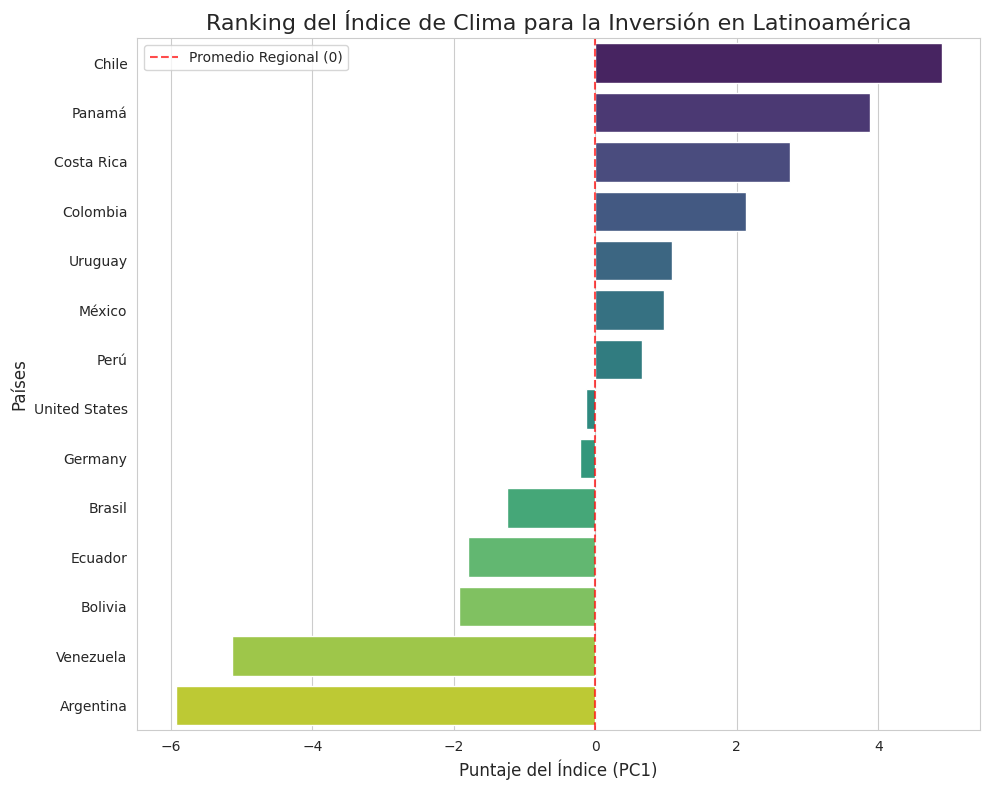

In [37]:
plt.figure(figsize=(10, 8))
sns.barplot(
    x='Indice_Inversion',
    y='ShortName',
    data=df_final,
    palette='viridis',
    hue='ShortName',
    legend=False
)

plt.title('Ranking del Índice de Clima para la Inversión en Latinoamérica', fontsize=16)
plt.xlabel('Puntaje del Índice (PC1)', fontsize=12)
plt.ylabel('Países', fontsize=12)
plt.axvline(x=0, color='red', linestyle='--', alpha=0.7, label='Promedio Regional (0)')
plt.legend()
plt.tight_layout()
plt.show()

7.4. Analiza los resultados del gráfico y redacta una conclusiones para el MinCIT sobre el clima de inversión en la región, quiénes son nuestros competidores en la atracción de capitales extranjeros y por qué, en qué son mejores que Colombia.

De acuerdo con el gráfico, se observa que Chile ocupa el primer lugar en el índice de clima de inversión, seguido de Panamá, Costa Rica y Colombia. Esto muestra que Colombia tiene una posición favorable dentro del grupo analizado, pero todavía existen países de la región que presentan mejores condiciones para atraer capital extranjero.

Los principales competidores de Colombia son Chile, Panamá y Costa Rica, ya que se encuentran por encima del país en el ranking. Chile se destaca por la estabilidad de sus instituciones, la seguridad jurídica y las condiciones que ofrece para desarrollar negocios. Panamá tiene una ventaja por su ubicación geográfica, su conexión con los mercados internacionales y su papel como centro logístico y financiero. Por su parte, Costa Rica ha logrado atraer inversión extranjera en sectores como los dispositivos médicos, los servicios empresariales y la tecnología.

En comparación con estos países, Colombia necesita seguir mejorando aspectos como la seguridad jurídica, la agilidad de los trámites, la infraestructura y la estabilidad económica. Estos factores son importantes porque las empresas extranjeras buscan países donde puedan invertir con menores niveles de incertidumbre y desarrollar sus actividades de manera eficiente.

Por otro lado, el gráfico muestra que Uruguay, México y Perú también presentan resultados positivos, aunque inferiores a los de Colombia. Estos países pueden representar competencia para atraer inversiones, especialmente en sectores como la industria, los servicios, la minería y el comercio internacional.

También se observa que Brasil, Ecuador, Bolivia, Venezuela y Argentina presentan valores negativos en el índice. Sin embargo, esto no significa necesariamente que no reciban inversión extranjera, sino que, según las variables utilizadas para construir el indicador, sus resultados son inferiores al promedio regional representado en el gráfico.

Colombia cuenta con una posición competitiva para atraer capital extranjero, pero necesita fortalecer sus condiciones de inversión para acercarse a países como Chile, Panamá y Costa Rica. Para lograrlo, el Ministerio de Comercio, Industria y Turismo (MinCIT) podría impulsar medidas orientadas a simplificar los trámites empresariales, mejorar la infraestructura logística, fortalecer la seguridad jurídica y promover una mayor estabilidad en las reglas que afectan a los inversionistas.

Asimismo, sería importante aprovechar las ventajas de Colombia, como su ubicación geográfica, el tamaño de su mercado y la diversidad de sus sectores productivos, para atraer inversiones en actividades que generen empleo, transferencia de tecnología y crecimiento económico.

En conclusión, el principal reto de Colombia no es solamente atraer más inversión extranjera, sino ofrecer condiciones competitivas y estables que permitan mantenerla en el tiempo. Para ello, resulta importante observar las experiencias de Chile, Panamá y Costa Rica e identificar qué políticas podrían adaptarse a las necesidades del país. De esta manera, Colombia podría mejorar su posición en la región y aprovechar la inversión extranjera como una herramienta para impulsar el desarrollo económico.